## Setup
Environment, imports, configuration printout. Nothing here changes any data.

In [1]:
import sys, subprocess
import os

In [2]:
import sys, os
print(sys.executable)      # the python being used right now
print(sys.prefix)          # the environment folder
print(sys.version)
print(os.environ.get("VIRTUAL_ENV"), os.environ.get("CONDA_DEFAULT_ENV"))

/home/aa8624/thesis_2500/venv/bin/python
/home/aa8624/thesis_2500/venv
3.12.3 (main, Mar 23 2026, 19:04:32) [GCC 13.3.0]
None None


In [3]:
# List the key package versions in this environment 
print("python:", sys.executable)
print(subprocess.run([sys.executable, "-m", "pip", "list"], capture_output=True, text=True).stdout
      .split("\n")[0:0] or "")
out = subprocess.run([sys.executable, "-m", "pip", "list"], capture_output=True, text=True).stdout
print("\n".join(l for l in out.splitlines() if l.lower().split()[0:1] and l.lower().split()[0] in
      ("torch", "torchvision", "torchaudio", "transformers", "huggingface-hub", "open_clip_torch", "open-clip-torch")))

python: /home/aa8624/thesis_2500/venv/bin/python

open_clip_torch           3.3.0
torch                     2.11.0+cu128
torchvision               0.26.0+cu128
transformers              5.13.0


In [4]:
#Pick the GPU (index from nvidia-smi)
# a quiet GPU index from nvidia-smi
os.environ["CUDA_VISIBLE_DEVICES"] = "3"   

In [5]:
# Imports and config printout. 
import sys, importlib
from pathlib import Path
sys.path.insert(0, str(Path.cwd()))         
import warnings; warnings.filterwarnings("ignore")
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import size_config as sc
import config
from sklearn.metrics import roc_auc_score
from sklearn.linear_model import LogisticRegressionCV, LogisticRegression
from sklearn.preprocessing import StandardScaler

%matplotlib inline
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 50)


print("PROJECT_ROOT :", config.PROJECT_ROOT)
print("QUICK_RUN    :", config.QUICK_RUN, "  (True = tiny settings, NOT for final results)")
print("family set   :", config.ACTIVE_FAMILY_SET, "| models:", config.MODELS_TO_RUN)
print("seeds        :", config.EXPERIMENT_SEEDS)
try:
    import torch; print("torch        :", torch.__version__, "| CUDA:", torch.cuda.is_available())
except ImportError:
    print("torch not installed (only the logistic-regression models will work)")

PROJECT_ROOT : /data/aa8624/thesis_2500
QUICK_RUN    : False   (True = tiny settings, NOT for final results)
family set   : diffusion_split | models: ['spectral_lr', 'handcrafted_lr', 'lbp_lr', 'cnn_densenet', 'supcon', 'npr', 'clip_frozen', 'biomedclip_frozen', 'rad_dino', 'dinov2_frozen']
seeds        : [42, 43, 44]
torch        : 2.11.0+cu128 | CUDA: True


In [6]:
# Number of data-loader workers for the CNN detectors
config.CNN_NUM_WORKERS = 4

**Optional installs (commented out on purpose).** These two lines change the Python environment, so they are not run
automatically. Uncomment and run them once if `import open_clip` or the Hugging Face hub version fails in Stage 5, then restart the kernel.

In [9]:
# One-off environment fixes. Execute only once.
!{sys.executable} -m pip uninstall -y huggingface-hub
!{sys.executable} -m pip install "huggingface-hub>=1.5,<2.0"
%pip install open_clip_torch

Found existing installation: huggingface_hub 1.33.0
Uninstalling huggingface_hub-1.33.0:
  Successfully uninstalled huggingface_hub-1.33.0
  Using cached huggingface_hub-1.33.0-py3-none-any.whl.metadata (16 kB)
Using cached huggingface_hub-1.33.0-py3-none-any.whl (846 kB)


Note: you may need to restart the kernel to use updated packages.


## Frequency characterisation 

#### Stage 3a — Extract the  forensic features

In [8]:
# Reload the feature modules
importlib.reload(config)                         

import stage3_forensics.feature_extractors as fe
import stage3_forensics.extract_features as ef
import stage3_forensics.statistical_analysis as sa
for m in (fe, ef, sa):                           
    importlib.reload(m)

In [9]:
# Check that the extraction settings come from the current config.py
import numpy as np
import config
from utils.common import load_gray_float01

# 'prepared' is the Stage 2c table. If the kernel was restarted, load it from disk instead:
try:
    prepared
except NameError:
    prepared = pd.read_csv(config.DET_PREPARED_MANIFEST, dtype={"subject_id": str, "study_id": str})

print("config file :", config.__file__)
print("image size  :", config.FORENSIC_CHARACTERISATION_IMAGE_SIZE, config.PREP_IMAGE_SIZE)   # 256 256
print("median size :", config.SPECTRAL_RESIDUAL_MEDIAN_SIZE)                                  # 3
print("n features  :", len(config.FEATURE_COLUMNS))                                           # 42
print("residual    :", config.RESIDUAL_SPECTRAL_FEATURES)                                     # 6 names starting specres_
print("groups      :", config.SCREENING_GROUPS, "| reference:", config.REFERENCE_GROUP)       # 8 groups | Real
print("prepared groups:", sorted(prepared["frequency_group"].unique()))

assert len(config.FEATURE_COLUMNS) == 42
assert set(config.SCREENING_GROUPS) <= set(prepared["frequency_group"]), "a screening group is missing"
assert hasattr(fe, "spectral_features_residual") and hasattr(ef, "extract_residual_features")

img = load_gray_float01(prepared["prepared_path"].iloc[0])
print("image       :", img.shape, img.dtype, f"range [{img.min():.3f}, {img.max():.3f}]")
assert img.shape == (256, 256) and 0.0 <= img.min() and img.max() <= 1.0

f, _ = fe.extract_feature_dict(img)
r, _ = fe.spectral_features_residual(img)
assert np.isfinite(list(f.values())).all() and np.isfinite(list(r.values())).all()
print(len(f), "features,", len(r), "residual features:", list(r))

config file : /data/aa8624/thesis_2500/cxr_forensics/config.py
image size  : 256 256
median size : 3
n features  : 42
residual    : ['specres_hfer', 'specres_slope', 'specres_slope_r', 'specres_anisotropy', 'specres_total_energy', 'specres_high_energy']
groups      : ['Real', 'IP_Blob', 'IP_CopyMove', 'IP_TextureTransplant', 'CycleGAN', 'Diffusion', 'Diffusion_EditOnly', 'Diffusion_Reconstruction'] | reference: Real
prepared groups: ['CycleGAN', 'Diffusion', 'Diffusion_EditOnly', 'Diffusion_Reconstruction', 'IP_Blob', 'IP_CopyMove', 'IP_TextureTransplant', 'Real']
image       : (256, 256) float32 range [0.000, 1.000]
42 features, 6 residual features: ['specres_hfer', 'specres_slope', 'specres_slope_r', 'specres_anisotropy', 'specres_total_energy', 'specres_high_energy']


In [11]:
import time, numpy as np, pandas as pd

sub = pd.concat(
    [g.sample(min(3, len(g)), random_state=0) for _, g in prepared.groupby("frequency_group")]
).reset_index(drop=True)
print(len(sub), "images,", sub["frequency_group"].nunique(), "groups")

t = time.time()
try:
    f = ef.extract_all_features(sub, n_jobs=1)      # serial, no worker pool
except TypeError:
    f = ef.extract_all_features(sub)                # function has no n_jobs argument
dt = time.time() - t

print(f"{dt:.1f} s total -> {dt/len(sub):.2f} s/image")
print(f"estimated for all {len(prepared)} images on one core: {dt/len(sub)*len(prepared)/60:.0f} min")
print(f"with 16 workers: ~{dt/len(sub)*len(prepared)/16/60:.0f} min")
print(f.shape, "| finite:", np.isfinite(f[config.FEATURE_COLUMNS].to_numpy()).all())

24 images, 8 groups
Extracting 42 features from 24 images (n_jobs=1) ...
Saved 24 rows -> /data/aa8624/thesis_2500/data/artifact_characterization/stage1_characterisation/per_image_forensic_characteristics.csv
2.2 s total -> 0.09 s/image
estimated for all 19973 images on one core: 30 min
with 16 workers: ~2 min
(24, 62) | finite: True


In [10]:
features = ef.extract_all_features(prepared, n_jobs=1)
print(features.shape)
print(features["frequency_group"].value_counts())

assert len(features) == len(prepared), "some images were lost"
assert features["image_id"].is_unique
assert np.isfinite(features[config.FEATURE_COLUMNS].to_numpy()).all()

Extracting 42 features from 19973 images (n_jobs=1) ...
Saved 19973 rows -> /data/aa8624/thesis_2500/data/artifact_characterization/stage1_characterisation/per_image_forensic_characteristics.csv
(19973, 62)
frequency_group
Real                        2500
IP_Blob                     2500
IP_CopyMove                 2500
IP_TextureTransplant        2500
CycleGAN                    2500
Diffusion                   2491
Diffusion_EditOnly          2491
Diffusion_Reconstruction    2491
Name: count, dtype: int64


In [13]:
# Load the radial spectral profiles and take a first look at the spectral features
profiles = ef.load_radial_profiles()                  # indexed by image_id, 64 columns

assert profiles.shape == (len(features), 64), profiles.shape
assert set(profiles.index) == set(features["image_id"]), "profiles and features cover different images"

(features[["frequency_group"] + config.FEATURE_COLUMNS[:6]]
    .groupby("frequency_group").mean().round(4))

,spectral_hfer,spectral_slope,spectral_slope_r,spectral_anisotropy,spectral_total_energy,spectral_high_energy
frequency_group,,,,,,
CycleGAN,0.0030,-3.0131,-0.9918,0.4343,596.5105,1.7551
Diffusion,0.0022,-3.2195,-0.9956,0.4851,578.3489,1.2483
Diffusion_EditOnly,0.0027,-3.0887,-0.9956,0.4741,590.0020,1.6024
Diffusion_Reconstruction,0.0021,-3.1868,-0.9959,0.4911,592.3207,1.2476
IP_Blob,0.0029,-3.1258,-0.9963,0.4381,548.8085,1.5728
IP_CopyMove,0.0027,-3.1431,-0.9963,0.4934,591.9723,1.5987
IP_TextureTransplant,0.0027,-3.1451,-0.9963,0.4634,591.8235,1.6074
Real,0.0028,-3.0371,-0.9958,0.4661,603.4197,1.7031


## Stage 3b — Descriptive statistics

For each of the 42 features and each group, on the training split only, we report the mean, spread (standard deviation, median, IQR) and the shift from the Real group.

A single-feature AUROC (one group against the rest) ranks the features by how well each separates a group on its own, and counts how many features carry signal for each group.

A Spearman correlation between features finds near-duplicates ($\lvert\rho\rvert > 0.95$) so they can be dropped before modelling.

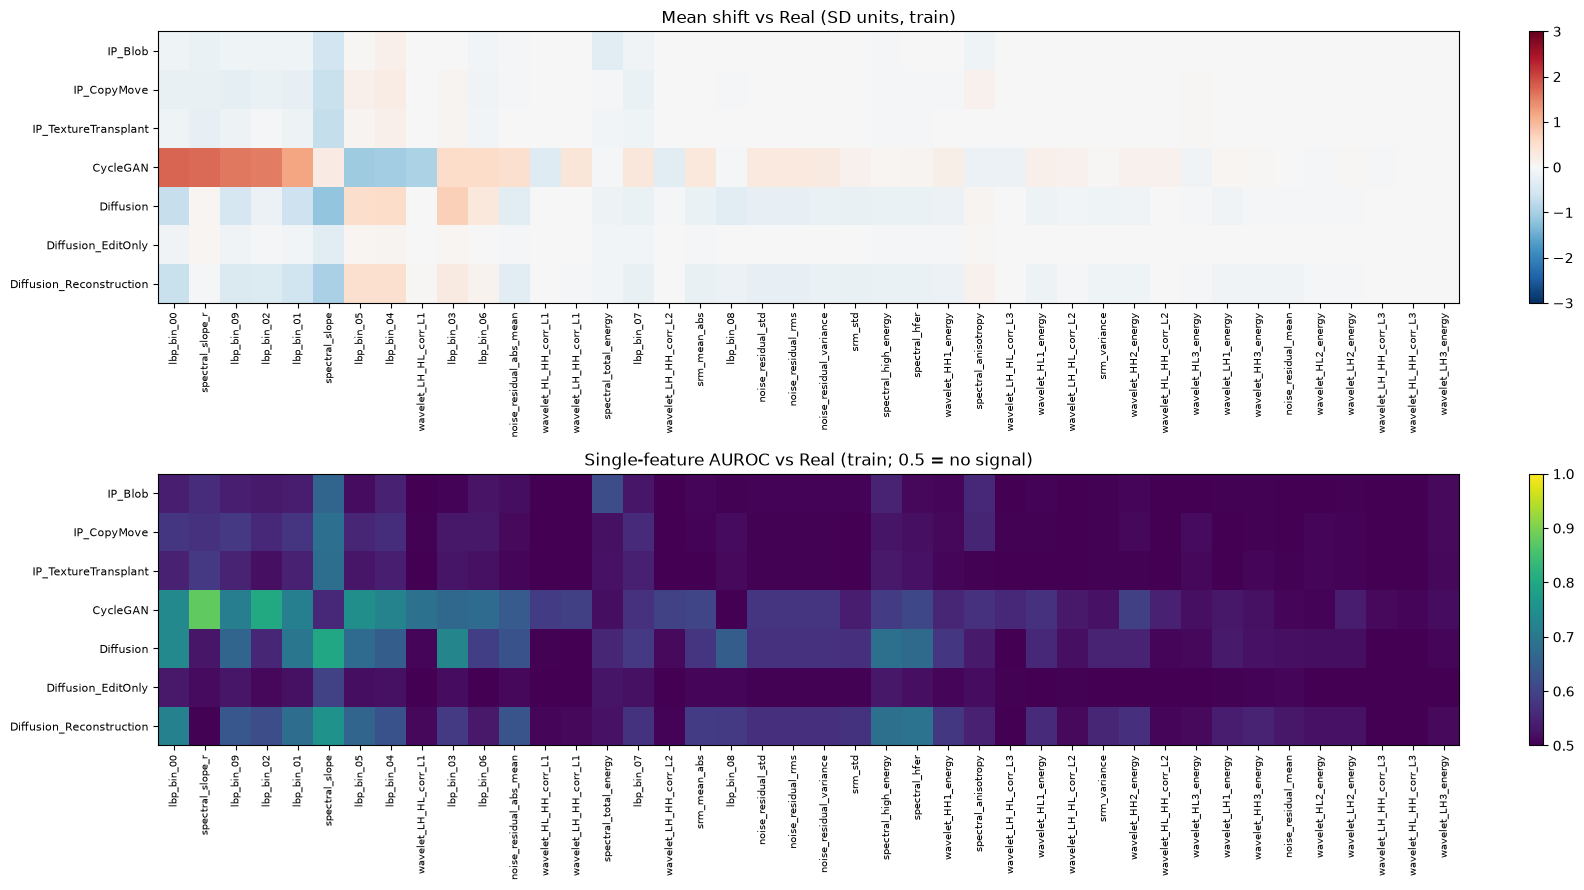

In [14]:
F      = list(config.FEATURE_COLUMNS)
REF    = config.REFERENCE_GROUP                                   # "Real"
groups = [g for g in config.SCREENING_GROUPS if g != REF]         # the 7 synthetic groups
tr     = features[features.split == config.SCREENING_SPLIT]       # train only

ref = tr[tr.frequency_group == REF]
assert len(ref) > 0, f"no '{REF}' rows in the {config.SCREENING_SPLIT} split"
mu, sd = ref[F].mean(), ref[F].std()

def group_rows(g):
    d = tr[tr.frequency_group == g]
    assert len(d) > 0, f"no rows for {g}"
    return d

# 1) standardised mean shift vs Real (SD units of the real group)
shift = pd.DataFrame({g: (group_rows(g)[F].mean() - mu) / sd for g in groups}).T

# 2) single-feature AUROC, real vs group (direction-free: 0.5 = no signal)
def auroc_vs_ref(g):
    d = group_rows(g)
    y = np.r_[np.zeros(len(ref)), np.ones(len(d))]
    return [roc_auc_score(y, np.r_[ref[f], d[f]]) for f in F]

au = pd.DataFrame({g: auroc_vs_ref(g) for g in groups}, index=F).T
au = (au - 0.5).abs() + 0.5

order = shift.abs().max(axis=0).sort_values(ascending=False).index    # strongest features first
fig, axes = plt.subplots(2, 1, figsize=(16, 9))
for ax, M, title, cmap, kw in [
        (axes[0], shift[order], f"Mean shift vs {REF} (SD units, train)", "RdBu_r", dict(vmin=-3, vmax=3)),
        (axes[1], au[order],    "Single-feature AUROC vs Real (train; 0.5 = no signal)", "viridis", dict(vmin=0.5, vmax=1))]:
    im = ax.imshow(M.values, aspect="auto", cmap=cmap, **kw)
    ax.set_yticks(range(len(M))); ax.set_yticklabels(M.index, fontsize=8)
    ax.set_xticks(range(M.shape[1])); ax.set_xticklabels(M.columns, rotation=90, fontsize=7)
    ax.set_title(title); plt.colorbar(im, ax=ax, fraction=0.02)
plt.tight_layout(); plt.show()

#### Unimportant features

In [15]:
import numpy as np, pandas as pd, config
import stage3_forensics.statistical_analysis as sa

F   = list(config.FEATURE_COLUMNS)
thr = config.REDUNDANCY_SPEARMAN_THRESHOLD
tr  = features[(features.split == config.SCREENING_SPLIT)
               & features.frequency_group.isin(config.SCREENING_GROUPS)]

# 1) near-duplicate pairs
C = tr[F].corr(method="spearman").abs()
pairs = (C.where(np.triu(np.ones(C.shape), k=1).astype(bool)).stack()
           .sort_values(ascending=False))
print(f"pairs with |rho| > {thr}:")
print(pairs[pairs > thr].head(30).round(3))

# 2) what the pipeline actually keeps and drops (strongest feature of each pair is kept)
kw = sa.kruskal_table(tr, F, config.SCREENING_GROUP_COLUMN)
kept, dropped = sa.redundancy_pruning(tr, F, kw)
print(f"\nkept {len(kept)} of {len(F)} features; dropped {len(dropped)}:")
print(dropped.round(3).to_string(index=False))

pairs with |rho| > 0.95:
noise_residual_std       noise_residual_rms    1.000
noise_residual_variance  noise_residual_rms    1.000
                         noise_residual_std    1.000
srm_variance             srm_std               0.959
dtype: float64

kept 39 of 42 features; dropped 3:
   dropped_feature            duplicate_of  spearman_abs family
noise_residual_std noise_residual_variance         1.000  noise
noise_residual_rms noise_residual_variance         1.000  noise
      srm_variance                 srm_std         0.959    srm


#### Rnaking features based on generator type

In [16]:
import stage3_forensics.statistical_analysis as sa

REF  = config.REFERENCE_GROUP
tr   = features[(features.split == config.SCREENING_SPLIT)
                & features.frequency_group.isin(config.SCREENING_GROUPS)]

# Features kept after redundancy pruning, on the same data and rule as the pipeline
kw   = sa.kruskal_table(tr, list(config.FEATURE_COLUMNS), config.SCREENING_GROUP_COLUMN)
F, dropped = sa.redundancy_pruning(tr, list(config.FEATURE_COLUMNS), kw)
print(f"{len(F)} features kept, {len(dropped)} dropped:", dropped["dropped_feature"].tolist())

ref  = tr[tr.frequency_group == REF]
fams = ["CycleGAN", "Diffusion", "Diffusion_Reconstruction", "Diffusion_EditOnly",
        "IP_Blob", "IP_CopyMove", "IP_TextureTransplant"]

def auc_signed(g):
    t = tr[tr.frequency_group == g]
    y = np.r_[np.zeros(len(ref)), np.ones(len(t))]
    return pd.Series({f: roc_auc_score(y, np.r_[ref[f], t[f]]) for f in F})

for g in fams:
    s = auc_signed(g)
    r = pd.DataFrame({"AUROC": ((s - 0.5).abs() + 0.5).round(3),
                      "direction": np.where(s >= 0.5, "higher than real", "lower than real")})
    r = r.sort_values("AUROC", ascending=False)
    r.insert(0, "rank", range(1, len(r) + 1))
    print(f"\n===== {g}: all {len(r)} features ranked =====")
    print(r.to_string())

39 features kept, 3 dropped: ['noise_residual_std', 'noise_residual_rms', 'srm_variance']

===== CycleGAN: all 39 features ranked =====
                         rank  AUROC         direction
spectral_slope_r            1  0.879  higher than real
lbp_bin_02                  2  0.803  higher than real
lbp_bin_05                  3  0.747   lower than real
lbp_bin_00                  4  0.735  higher than real
lbp_bin_04                  5  0.724   lower than real
lbp_bin_01                  6  0.715  higher than real
lbp_bin_09                  7  0.713  higher than real
wavelet_LH_HL_corr_L1       8  0.689   lower than real
lbp_bin_06                  9  0.674  higher than real
lbp_bin_03                 10  0.668  higher than real
noise_residual_abs_mean    11  0.643  higher than real
spectral_hfer              12  0.608  higher than real
srm_mean_abs               13  0.604  higher than real
wavelet_LH_HH_corr_L2      14  0.598   lower than real
wavelet_LH_HH_corr_L1      15  0.594  h


===== IP_CopyMove: all 39 features ranked =====
                         rank  AUROC         direction
spectral_slope              1  0.683   lower than real
lbp_bin_09                  2  0.583   lower than real
lbp_bin_00                  3  0.578   lower than real
lbp_bin_01                  4  0.576   lower than real
spectral_slope_r            5  0.571   lower than real
lbp_bin_04                  6  0.566  higher than real
lbp_bin_07                  7  0.562   lower than real
lbp_bin_02                  8  0.556   lower than real
lbp_bin_05                  9  0.553  higher than real
spectral_anisotropy        10  0.552  higher than real
lbp_bin_03                 11  0.533  higher than real
lbp_bin_06                 12  0.533   lower than real
spectral_high_energy       13  0.529   lower than real
spectral_total_energy      14  0.523   lower than real
spectral_hfer              15  0.521   lower than real
lbp_bin_08                 16  0.515   lower than real
wavelet_HL3_ener

#### Top 3 important features

In [17]:
REF = config.REFERENCE_GROUP
tr  = features[(features.split == config.SCREENING_SPLIT)
               & features.frequency_group.isin(config.SCREENING_GROUPS)]

# Features kept after redundancy pruning (same data and rule as the pipeline)
kw = sa.kruskal_table(tr, list(config.FEATURE_COLUMNS), config.SCREENING_GROUP_COLUMN)
F, dropped = sa.redundancy_pruning(tr, list(config.FEATURE_COLUMNS), kw)
print(f"{len(F)} features kept; dropped: {dropped['dropped_feature'].tolist()}")

ref  = tr[tr.frequency_group == REF]
fams = ["CycleGAN", "Diffusion", "Diffusion_Reconstruction", "Diffusion_EditOnly",
        "IP_Blob", "IP_CopyMove", "IP_TextureTransplant"]

def auc_signed(g):
    t = tr[tr.frequency_group == g]
    y = np.r_[np.zeros(len(ref)), np.ones(len(t))]
    return pd.Series({f: roc_auc_score(y, np.r_[ref[f], t[f]]) for f in F})

S = pd.DataFrame({g: auc_signed(g) for g in fams})
A = (S - 0.5).abs() + 0.5                                  # strength, direction removed

# 1) top 3 per group, with strength and direction
rows = []
for g in fams:
    for rank, f in enumerate(A[g].sort_values(ascending=False).head(3).index, 1):
        rows.append((g, rank, f, round(A.loc[f, g], 3), "higher" if S.loc[f, g] >= 0.5 else "lower"))
top3 = pd.DataFrame(rows, columns=["family", "rank", "feature", "AUROC", "vs real"])
display(top3.pivot(index="family", columns="rank", values="feature").loc[fams])
display(top3)

# 2) which features recur across groups in the top 3 and top 5
for k in (3, 5):
    tops = {g: set(A[g].sort_values(ascending=False).head(k).index) for g in fams}
    cnt = pd.Series([f for s in tops.values() for f in s]).value_counts()
    out = pd.DataFrame({"in how many families": cnt,
                        "which families": [", ".join(g for g in fams if f in tops[g]) for f in cnt.index]})
    print(f"\nFeatures that appear in the top {k} of more than one family:")
    display(out[out["in how many families"] > 1])

39 features kept; dropped: ['noise_residual_std', 'noise_residual_rms', 'srm_variance']


rank,1,2,3
family,,,
CycleGAN,spectral_slope_r,lbp_bin_02,lbp_bin_05
Diffusion,spectral_slope,lbp_bin_00,lbp_bin_03
Diffusion_Reconstruction,spectral_slope,lbp_bin_00,spectral_hfer
Diffusion_EditOnly,spectral_slope,lbp_bin_00,spectral_high_energy
IP_Blob,spectral_slope,spectral_total_energy,spectral_slope_r
IP_CopyMove,spectral_slope,lbp_bin_09,lbp_bin_00
IP_TextureTransplant,spectral_slope,spectral_slope_r,lbp_bin_09


,family,rank,feature,AUROC,vs real
0,CycleGAN,1,spectral_slope_r,0.879,higher
1,CycleGAN,2,lbp_bin_02,0.803,higher
2,CycleGAN,3,lbp_bin_05,0.747,lower
3,Diffusion,1,spectral_slope,0.800,lower
4,Diffusion,2,lbp_bin_00,0.735,lower
5,Diffusion,3,lbp_bin_03,0.728,higher
6,Diffusion_Reconstruction,1,spectral_slope,0.755,lower
7,Diffusion_Reconstruction,2,lbp_bin_00,0.720,lower
8,Diffusion_Reconstruction,3,spectral_hfer,0.690,lower
9,Diffusion_EditOnly,1,spectral_slope,0.596,lower



Features that appear in the top 3 of more than one family:


,in how many families,which families
spectral_slope,6,"Diffusion, Diffusion_Reconstruction, Diffusion..."
lbp_bin_00,4,"Diffusion, Diffusion_Reconstruction, Diffusion..."
spectral_slope_r,3,"CycleGAN, IP_Blob, IP_TextureTransplant"
lbp_bin_09,2,"IP_CopyMove, IP_TextureTransplant"



Features that appear in the top 5 of more than one family:


,in how many families,which families
lbp_bin_00,6,"CycleGAN, Diffusion, Diffusion_Reconstruction,..."
spectral_slope,6,"Diffusion, Diffusion_Reconstruction, Diffusion..."
spectral_slope_r,4,"CycleGAN, IP_Blob, IP_CopyMove, IP_TextureTran..."
lbp_bin_01,4,"Diffusion, Diffusion_Reconstruction, IP_CopyMo..."
spectral_high_energy,4,"Diffusion, Diffusion_Reconstruction, Diffusion..."
lbp_bin_09,3,"Diffusion_EditOnly, IP_CopyMove, IP_TextureTra..."
spectral_total_energy,2,"Diffusion_EditOnly, IP_Blob"


,features kept (of 39),test AUROC
family,,
IP_Blob,35,0.752
IP_CopyMove,38,0.743
IP_TextureTransplant,1,0.659
Diffusion_EditOnly,5,0.639
Diffusion_Reconstruction,35,0.844
Diffusion,35,0.901
CycleGAN,38,0.994


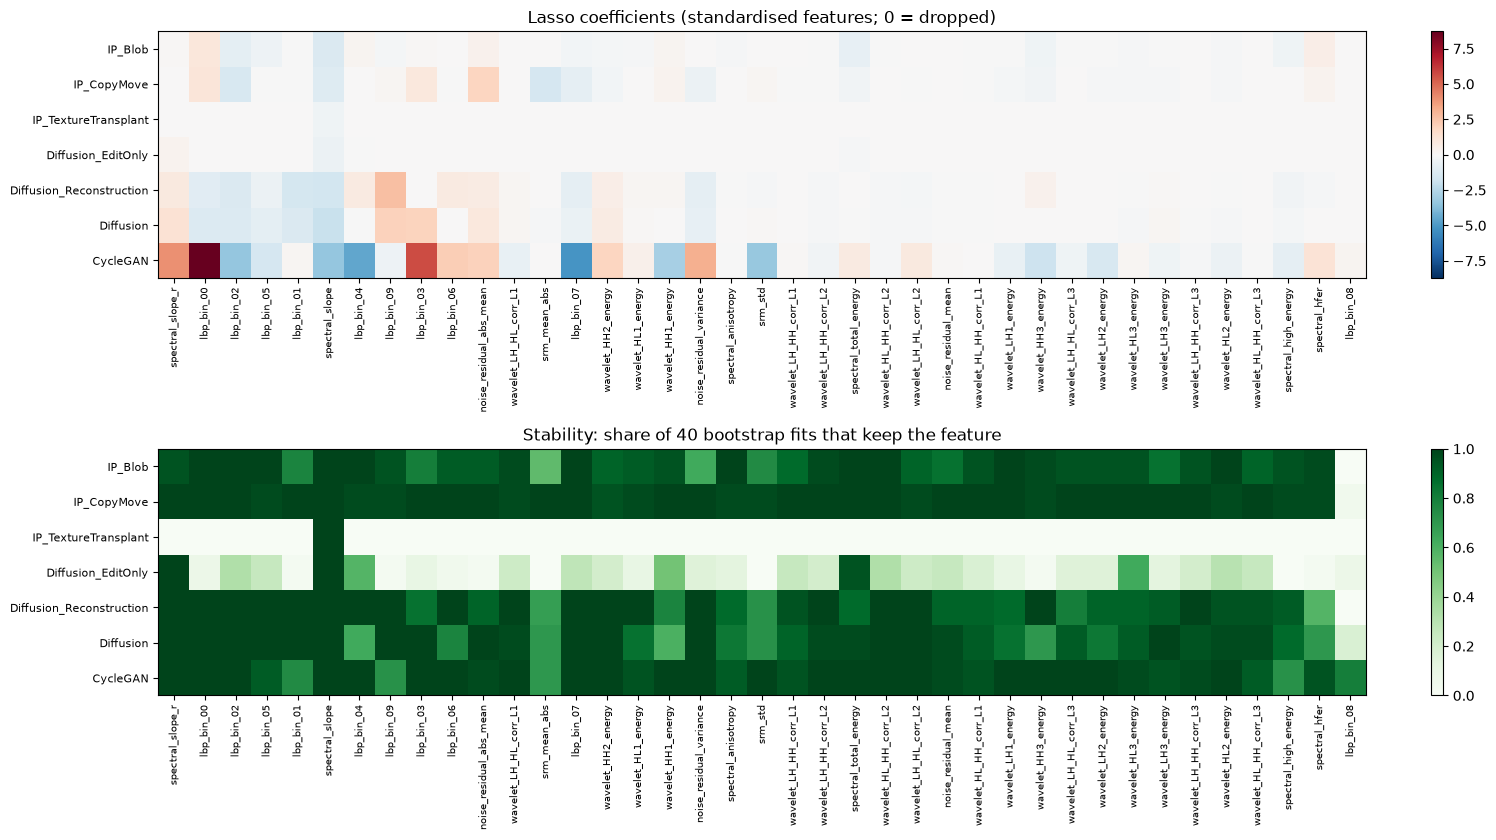

In [18]:
REF = config.REFERENCE_GROUP
trn = features[(features.split == config.SCREENING_SPLIT)
               & features.frequency_group.isin(config.SCREENING_GROUPS)]

# Features kept after redundancy pruning (same data and rule as the pipeline)
kw = sa.kruskal_table(trn, list(config.FEATURE_COLUMNS), config.SCREENING_GROUP_COLUMN)
F, _ = sa.redundancy_pruning(trn, list(config.FEATURE_COLUMNS), kw)

groups = ["IP_Blob", "IP_CopyMove", "IP_TextureTransplant", "Diffusion_EditOnly",
          "Diffusion_Reconstruction", "Diffusion", "CycleGAN"]
real = features[features.frequency_group == REF]
rng = np.random.default_rng(42)
N_BOOT = 40

W, FREQ, summ = {}, {}, []
for g in groups:
    d = pd.concat([real, features[features.frequency_group == g]])
    tr, te = d[d.split == "train"], d[d.split == "test"]
    ytr, yte = (tr.frequency_group == g).astype(int).values, (te.frequency_group == g).astype(int).values
    sc_ = StandardScaler().fit(tr[F]); Xtr, Xte = sc_.transform(tr[F]), sc_.transform(te[F])

    # lasso with the penalty chosen by 5-fold CV on the TRAIN split only
    m = LogisticRegressionCV(Cs=np.logspace(-3, 0.5, 15), penalty="l1", solver="liblinear",
                             scoring="roc_auc", cv=5, random_state=42).fit(Xtr, ytr)
    w = pd.Series(m.coef_[0], index=F); W[g] = w
    summ.append((g, int((w != 0).sum()), roc_auc_score(yte, m.decision_function(Xte))))

    # stability: how often is each feature kept across bootstrap resamples of the train set?
    C = m.C_[0]; keep = np.zeros(len(F))
    for _ in range(N_BOOT):
        i = rng.integers(0, len(ytr), len(ytr))
        b = LogisticRegression(penalty="l1", solver="liblinear", C=C).fit(Xtr[i], ytr[i])
        keep += (b.coef_[0] != 0)
    FREQ[g] = pd.Series(keep / N_BOOT, index=F)

S = pd.DataFrame(summ, columns=["family", f"features kept (of {len(F)})", "test AUROC"]).set_index("family")
display(S.round(3))

Wd, Fd = pd.DataFrame(W).T, pd.DataFrame(FREQ).T
cols = Fd.columns[Fd.max() >= 0.5]                         # kept in >=50% of resamples for some group
if len(cols) == 0:
    cols = Fd.max().sort_values(ascending=False).index[:10]
cols = Fd[cols].max().sort_values(ascending=False).index

vmax = max(np.abs(Wd[cols].values).max(), 1e-9)
fig, axes = plt.subplots(2, 1, figsize=(15, 8.5))
im  = axes[0].imshow(Wd[cols].values, aspect="auto", cmap="RdBu_r", vmin=-vmax, vmax=vmax)
axes[0].set_title("Lasso coefficients (standardised features; 0 = dropped)")
im2 = axes[1].imshow(Fd[cols].values, aspect="auto", cmap="Greens", vmin=0, vmax=1)
axes[1].set_title(f"Stability: share of {N_BOOT} bootstrap fits that keep the feature")
for ax, im_ in zip(axes, [im, im2]):
    ax.set_yticks(range(len(Wd))); ax.set_yticklabels(Wd.index, fontsize=8)
    ax.set_xticks(range(len(cols))); ax.set_xticklabels(cols, rotation=90, fontsize=7)
    plt.colorbar(im_, ax=ax, fraction=0.02)
plt.tight_layout(); plt.show()

#### Stage 3c — Logistic Regression

In [19]:
# Binary logistic regression: Real (0) vs one group (1). Fit on TRAIN, choose C on VAL, report TEST.
from sklearn.inspection import permutation_importance
from stage3_forensics.statistical_analysis import transform_features

REAL   = config.REFERENCE_GROUP
GROUPS = ["IP_Blob", "IP_CopyMove", "IP_TextureTransplant", "CycleGAN", "Diffusion",
          "Diffusion_EditOnly", "Diffusion_Reconstruction"]
FEATS  = list(config.FEATURE_COLUMNS)
ALL    = f"all {len(FEATS)}"
FAMS   = ["spectral", "wavelet", "lbp", "srm", "noise"]
SETS   = {ALL: FEATS, **{fam: [f for f in FEATS if config.FEATURE_FAMILY_OF[f] == fam] for fam in FAMS}}
rng    = np.random.default_rng(config.RANDOM_SEED)
table  = features

def fit_pair(g, cols):
    d = table[table.frequency_group.isin([REAL, g])]
    parts = {sp: d[d.split == sp] for sp in ("train", "val", "test")}
    y = {sp: (p.frequency_group == g).astype(int).to_numpy() for sp, p in parts.items()}
    sc_ = StandardScaler().fit(transform_features(parts["train"], cols))
    X = {sp: sc_.transform(transform_features(p, cols)) for sp, p in parts.items()}
    best = None
    for C in config.FORENSIC_LOGISTIC_C_GRID:
        clf = LogisticRegression(C=C, class_weight="balanced", max_iter=config.FORENSIC_LOGISTIC_MAX_ITER)
        clf.fit(X["train"], y["train"])
        a = roc_auc_score(y["val"], clf.predict_proba(X["val"])[:, 1])
        if best is None or a > best[0]:
            best = (a, C, clf)
    return best[2], X, y, parts

# def auroc_ci(y, p, n=1000):
def auroc_ci(y, p, n=300):
    vals = []
    for _ in range(n):
        b = rng.integers(0, len(y), len(y))
        if len(set(y[b])) == 2:
            vals.append(roc_auc_score(y[b], p[b]))
    return np.percentile(vals, [2.5, 97.5])

# ---- Table A: test AUROC with all features and with each family alone ----
rowsA, models = [], {}
for g in GROUPS:
    row = {"group": g}
    for name, cols in SETS.items():
        clf, X, y, parts = fit_pair(g, cols)
        p = clf.predict_proba(X["test"])[:, 1]
        row[name] = roc_auc_score(y["test"], p)
        if name == ALL:
            lo, hi = auroc_ci(y["test"], p)
            row[f"95% CI ({ALL})"] = f"[{lo:.2f}, {hi:.2f}]"
            models[g] = (clf, X, y, parts)
    rowsA.append(row)
A = pd.DataFrame(rowsA).set_index("group")
print(f"TEST AUROC, group vs {REAL} (0.5 = cannot tell apart)")
display(A.round(3))

# ---- Table B: top-5 features per group (permutation importance of the all-feature model on TEST) ----
for g in GROUPS:
    clf, X, y, parts = models[g]
    imp = permutation_importance(clf, X["test"], y["test"], scoring="roc_auc", n_repeats=20,
                                 random_state=config.RANDOM_SEED).importances_mean
    tr = parts["train"]
    rows = []
    for j in np.argsort(-imp)[:5]:
        f = FEATS[j]
        a = roc_auc_score(y["train"], tr[f].to_numpy())
        rows.append({"feature": f, "family": config.FEATURE_FAMILY_OF[f], "perm_importance": imp[j],
                     "direction": "higher in group" if clf.coef_[0][j] > 0 else "lower in group",
                     "single-feature AUROC (train)": max(a, 1 - a)})
    print(f"\n{g} vs {REAL}: top features")
    display(pd.DataFrame(rows).round(3))

TEST AUROC, group vs Real (0.5 = cannot tell apart)


,all 42,95% CI (all 42),spectral,wavelet,lbp,srm,noise
group,,,,,,,
IP_Blob,0.758,"[0.72, 0.79]",0.728,0.522,0.596,0.511,0.519
IP_CopyMove,0.744,"[0.71, 0.77]",0.697,0.527,0.655,0.523,0.517
IP_TextureTransplant,0.712,"[0.68, 0.74]",0.684,0.518,0.601,0.510,0.512
CycleGAN,0.994,"[0.99, 1.00]",0.889,0.797,0.967,0.600,0.626
Diffusion,0.902,"[0.88, 0.92]",0.848,0.619,0.845,0.601,0.609
Diffusion_EditOnly,0.651,"[0.61, 0.69]",0.638,0.524,0.546,0.513,0.514
Diffusion_Reconstruction,0.839,"[0.81, 0.86]",0.777,0.593,0.791,0.605,0.618



IP_Blob vs Real: top features


,feature,family,perm_importance,direction,single-feature AUROC (train)
0,spectral_slope,spectral,0.193,lower in group,0.664
1,spectral_total_energy,spectral,0.124,lower in group,0.617
2,lbp_bin_02,lbp,0.092,lower in group,0.536
3,lbp_bin_00,lbp,0.076,higher in group,0.543
4,lbp_bin_05,lbp,0.037,lower in group,0.517



IP_CopyMove vs Real: top features


,feature,family,perm_importance,direction,single-feature AUROC (train)
0,spectral_slope,spectral,0.209,lower in group,0.683
1,lbp_bin_02,lbp,0.141,lower in group,0.556
2,lbp_bin_07,lbp,0.078,lower in group,0.562
3,lbp_bin_00,lbp,0.066,higher in group,0.578
4,lbp_bin_03,lbp,0.062,higher in group,0.533


... (6 outputs left out)


Diffusion_EditOnly vs Real: top features


,feature,family,perm_importance,direction,single-feature AUROC (train)
0,spectral_slope,spectral,0.144,lower in group,0.596
1,lbp_bin_00,lbp,0.043,higher in group,0.534
2,spectral_slope_r,spectral,0.039,higher in group,0.514
3,lbp_bin_07,lbp,0.039,lower in group,0.522
4,spectral_total_energy,spectral,0.025,lower in group,0.529



Diffusion_Reconstruction vs Real: top features


,feature,family,perm_importance,direction,single-feature AUROC (train)
0,srm_std,srm,0.205,lower in group,0.572
1,spectral_slope,spectral,0.182,lower in group,0.755
2,lbp_bin_01,lbp,0.168,lower in group,0.679
3,srm_variance,srm,0.150,higher in group,0.554
4,lbp_bin_09,lbp,0.125,higher in group,0.635


In [11]:
# Binary logistic regression: Real (0) vs one group (1). Fit on TRAIN, choose C on VAL, report TEST.
from sklearn.inspection import permutation_importance
from stage3_forensics.statistical_analysis import transform_features

REAL   = config.REFERENCE_GROUP
GROUPS = ["IP_Blob", "IP_CopyMove", "IP_TextureTransplant", "CycleGAN", "Diffusion",
          "Diffusion_EditOnly", "Diffusion_Reconstruction"]
FEATS  = list(config.FEATURE_COLUMNS)
ALL    = f"all {len(FEATS)}"
FAMS   = ["spectral", "wavelet", "lbp", "srm", "noise"]
SETS   = {ALL: FEATS, **{fam: [f for f in FEATS if config.FEATURE_FAMILY_OF[f] == fam] for fam in FAMS}}
rng    = np.random.default_rng(config.RANDOM_SEED)
table  = features

def fit_pair(g, cols):
    d = table[table.frequency_group.isin([REAL, g])]
    parts = {sp: d[d.split == sp] for sp in ("train", "val", "test")}
    y = {sp: (p.frequency_group == g).astype(int).to_numpy() for sp, p in parts.items()}
    sc_ = StandardScaler().fit(transform_features(parts["train"], cols))
    X = {sp: sc_.transform(transform_features(p, cols)) for sp, p in parts.items()}
    best = None
    for C in config.FORENSIC_LOGISTIC_C_GRID:
        clf = LogisticRegression(C=C, class_weight="balanced", max_iter=config.FORENSIC_LOGISTIC_MAX_ITER)
        clf.fit(X["train"], y["train"])
        a = roc_auc_score(y["val"], clf.predict_proba(X["val"])[:, 1])
        if best is None or a > best[0]:
            best = (a, C, clf)
    return best[2], X, y, parts

def auroc_ci(y, p, n=1000):
# def auroc_ci(y, p, n=300):
    vals = []
    for _ in range(n):
        b = rng.integers(0, len(y), len(y))
        if len(set(y[b])) == 2:
            vals.append(roc_auc_score(y[b], p[b]))
    return np.percentile(vals, [2.5, 97.5])

# ---- Table A: test AUROC with all features and with each family alone ----
rowsA, models = [], {}
for g in GROUPS:
    row = {"group": g}
    for name, cols in SETS.items():
        clf, X, y, parts = fit_pair(g, cols)
        p = clf.predict_proba(X["test"])[:, 1]
        row[name] = roc_auc_score(y["test"], p)
        if name == ALL:
            lo, hi = auroc_ci(y["test"], p)
            row[f"95% CI ({ALL})"] = f"[{lo:.2f}, {hi:.2f}]"
            models[g] = (clf, X, y, parts)
    rowsA.append(row)
A = pd.DataFrame(rowsA).set_index("group")
print(f"TEST AUROC, group vs {REAL} (0.5 = cannot tell apart)")
display(A.round(3))

# ---- Table B: top-5 features per group (permutation importance of the all-feature model on TEST) ----
for g in GROUPS:
    clf, X, y, parts = models[g]
    imp = permutation_importance(clf, X["test"], y["test"], scoring="roc_auc", n_repeats=20,
                                 random_state=config.RANDOM_SEED).importances_mean
    tr = parts["train"]
    rows = []
    for j in np.argsort(-imp)[:5]:
        f = FEATS[j]
        a = roc_auc_score(y["train"], tr[f].to_numpy())
        rows.append({"feature": f, "family": config.FEATURE_FAMILY_OF[f], "perm_importance": imp[j],
                     "direction": "higher in group" if clf.coef_[0][j] > 0 else "lower in group",
                     "single-feature AUROC (train)": max(a, 1 - a)})
    print(f"\n{g} vs {REAL}: top features")
    display(pd.DataFrame(rows).round(3))

TEST AUROC, group vs Real (0.5 = cannot tell apart)


,all 42,95% CI (all 42),spectral,wavelet,lbp,srm,noise
group,,,,,,,
IP_Blob,0.758,"[0.73, 0.79]",0.728,0.522,0.596,0.511,0.519
IP_CopyMove,0.744,"[0.71, 0.77]",0.697,0.527,0.655,0.523,0.517
IP_TextureTransplant,0.712,"[0.68, 0.74]",0.684,0.518,0.601,0.510,0.512
CycleGAN,0.994,"[0.99, 1.00]",0.889,0.797,0.967,0.600,0.626
Diffusion,0.902,"[0.88, 0.92]",0.848,0.619,0.845,0.601,0.609
Diffusion_EditOnly,0.651,"[0.62, 0.69]",0.638,0.524,0.546,0.513,0.514
Diffusion_Reconstruction,0.839,"[0.81, 0.86]",0.777,0.593,0.791,0.605,0.618



IP_Blob vs Real: top features


,feature,family,perm_importance,direction,single-feature AUROC (train)
0,spectral_slope,spectral,0.193,lower in group,0.664
1,spectral_total_energy,spectral,0.124,lower in group,0.617
2,lbp_bin_02,lbp,0.092,lower in group,0.536
3,lbp_bin_00,lbp,0.076,higher in group,0.543
4,lbp_bin_05,lbp,0.037,lower in group,0.517



IP_CopyMove vs Real: top features


,feature,family,perm_importance,direction,single-feature AUROC (train)
0,spectral_slope,spectral,0.209,lower in group,0.683
1,lbp_bin_02,lbp,0.141,lower in group,0.556
2,lbp_bin_07,lbp,0.078,lower in group,0.562
3,lbp_bin_00,lbp,0.066,higher in group,0.578
4,lbp_bin_03,lbp,0.062,higher in group,0.533


... (6 outputs left out)


Diffusion_EditOnly vs Real: top features


,feature,family,perm_importance,direction,single-feature AUROC (train)
0,spectral_slope,spectral,0.144,lower in group,0.596
1,lbp_bin_00,lbp,0.043,higher in group,0.534
2,spectral_slope_r,spectral,0.039,higher in group,0.514
3,lbp_bin_07,lbp,0.039,lower in group,0.522
4,spectral_total_energy,spectral,0.025,lower in group,0.529



Diffusion_Reconstruction vs Real: top features


,feature,family,perm_importance,direction,single-feature AUROC (train)
0,srm_std,srm,0.205,lower in group,0.572
1,spectral_slope,spectral,0.182,lower in group,0.755
2,lbp_bin_01,lbp,0.168,lower in group,0.679
3,srm_variance,srm,0.150,higher in group,0.554
4,lbp_bin_09,lbp,0.125,higher in group,0.635


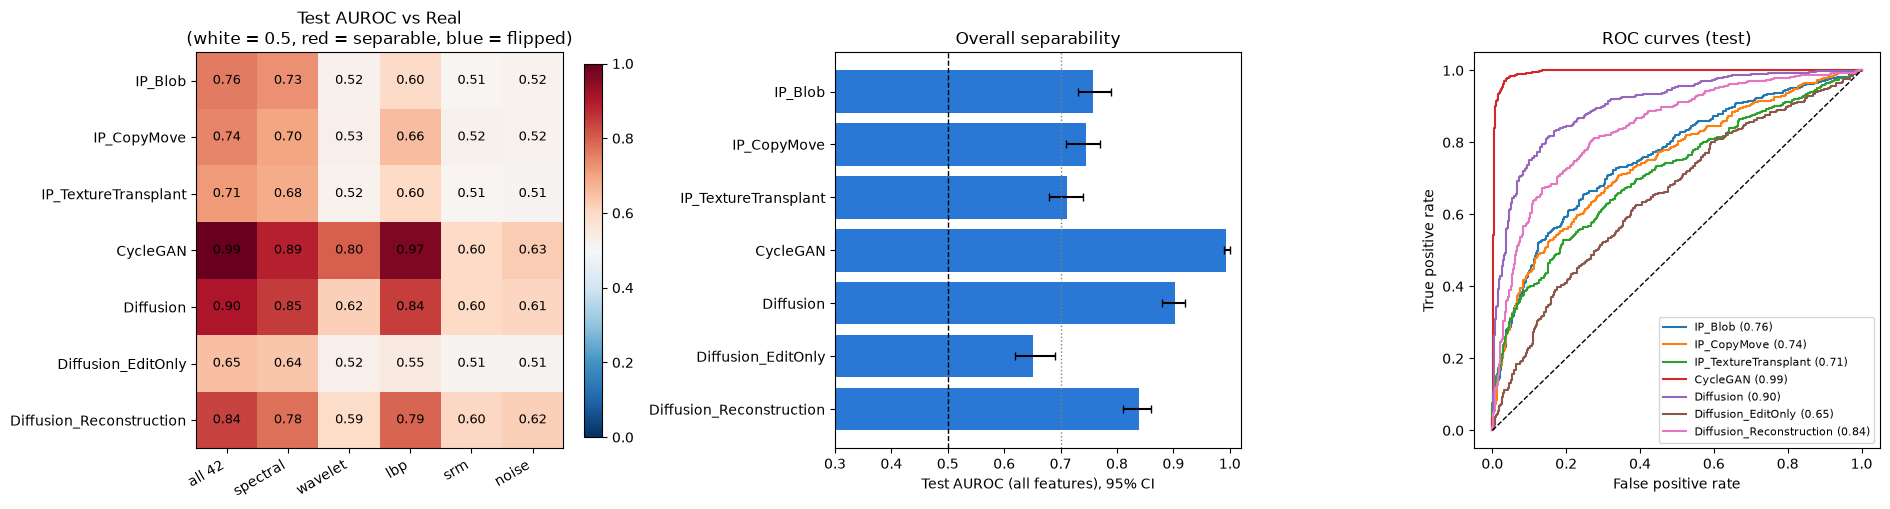

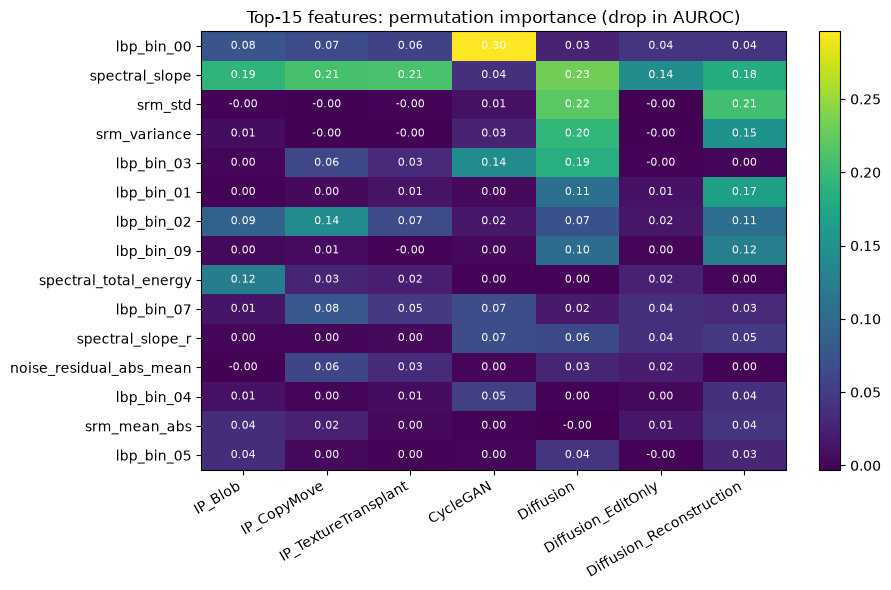

In [15]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.inspection import permutation_importance

# ---------- Figure 1: how separable is each group from real? ----------
fig, ax = plt.subplots(1, 3, figsize=(19, 5.2))

# (a) test AUROC by feature family
M = A[["all 42", "spectral", "wavelet", "lbp", "srm", "noise"]].astype(float)
im = ax[0].imshow(M.values, cmap="RdBu_r", vmin=0.0, vmax=1.0, aspect="auto")
ax[0].set_xticks(range(M.shape[1])); ax[0].set_xticklabels(M.columns, rotation=30, ha="right")
ax[0].set_yticks(range(M.shape[0])); ax[0].set_yticklabels(M.index)
for i in range(M.shape[0]):
    for j in range(M.shape[1]):
        ax[0].text(j, i, f"{M.values[i, j]:.2f}", ha="center", va="center", fontsize=9)
ax[0].set_title("Test AUROC vs Real\n(white = 0.5, red = separable, blue = flipped)")
plt.colorbar(im, ax=ax[0], fraction=0.046)

# (b) overall AUROC with 95% CI
ci = A["95% CI (all 42)"].str.strip("[]").str.split(",", expand=True).astype(float)
v = A["all 42"].astype(float).values
ax[1].barh(A.index, v, xerr=[v - ci[0].values, ci[1].values - v], color="#2a78d6", capsize=3)
ax[1].axvline(0.5, color="k", ls="--", lw=1); ax[1].axvline(0.70, color="grey", ls=":", lw=1)
ax[1].set_xlim(0.3, 1.02); ax[1].invert_yaxis()
ax[1].set_xlabel("Test AUROC (all features), 95% CI"); ax[1].set_title("Overall separability")

# (c) ROC curves
for g, (c, X_, yy, parts_) in models.items():
    p = c.predict_proba(X_["test"])[:, 1]; fpr, tpr, _ = roc_curve(yy["test"], p)
    ax[2].plot(fpr, tpr, label=f"{g} ({roc_auc_score(yy['test'], p):.2f})")
ax[2].plot([0, 1], [0, 1], "k--", lw=1)
ax[2].set_xlabel("False positive rate"); ax[2].set_ylabel("True positive rate")
ax[2].set_title("ROC curves (test)"); ax[2].legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.savefig("lr_fig1_separability.png", dpi=150); plt.show()

# ---------- Figure 2: which features matter for which group ----------
imps = {}
for g, (c, X_, yy, parts_) in models.items():
    if g == "Real_Source": continue                      # control group
#     imps[g] = permutation_importance(c, X_["test"], yy["test"], scoring="roc_auc",
#                                      n_repeats=10, random_state=0).importances_mean
    imps[g] = permutation_importance(c, X_["test"], yy["test"], scoring="roc_auc",
                                 n_repeats=20, random_state=config.RANDOM_SEED).importances_mean
I = pd.DataFrame(imps, index=FEATS)
Is = I.loc[I.max(axis=1).sort_values(ascending=False).head(15).index]
fig, ax = plt.subplots(figsize=(9, 6))
im = ax.imshow(Is.values, cmap="viridis", aspect="auto")
ax.set_xticks(range(Is.shape[1])); ax.set_xticklabels(Is.columns, rotation=30, ha="right")
ax.set_yticks(range(Is.shape[0])); ax.set_yticklabels(Is.index)
for i in range(Is.shape[0]):
    for j in range(Is.shape[1]):
        ax.text(j, i, f"{Is.values[i, j]:.2f}", ha="center", va="center", color="w", fontsize=8)
ax.set_title("Top-15 features: permutation importance (drop in AUROC)")
plt.colorbar(im, ax=ax, fraction=0.046); plt.tight_layout()
plt.savefig("lr_fig2_features.png", dpi=150); plt.show()

In [17]:
# Setup so the plotting cell runs on its own
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd()))        

import numpy as np, pandas as pd, matplotlib.pyplot as plt
import config
import stage3_forensics.statistical_analysis as sa

features = pd.read_csv(config.FORENSIC_FEATURE_CSV,
                       dtype={"subject_id": str, "study_id": str})
print(features.shape)                      # expect (19973, 62)

res = sa.run_stage3_analysis(features, profiles=None, make_plots=False)   # train split, 8 groups
print(len(res["kept_features"]), "kept,", len(res["redundancy"]), "dropped")

(19973, 62)
Screening on split='train': 11985 images, 8 groups
frequency_group
Real                        1500
IP_Blob                     1500
IP_CopyMove                 1500
IP_TextureTransplant        1500
CycleGAN                    1500
Diffusion                   1495
Diffusion_EditOnly          1495
Diffusion_Reconstruction    1495
Redundancy pruning (Spearman |rho| > 0.95): 39 of 42 features kept, 3 dropped
Saved Stage-3 tables -> /data/aa8624/thesis_2500/data/artifact_characterization/stage1_characterisation/analysis
39 kept, 3 dropped


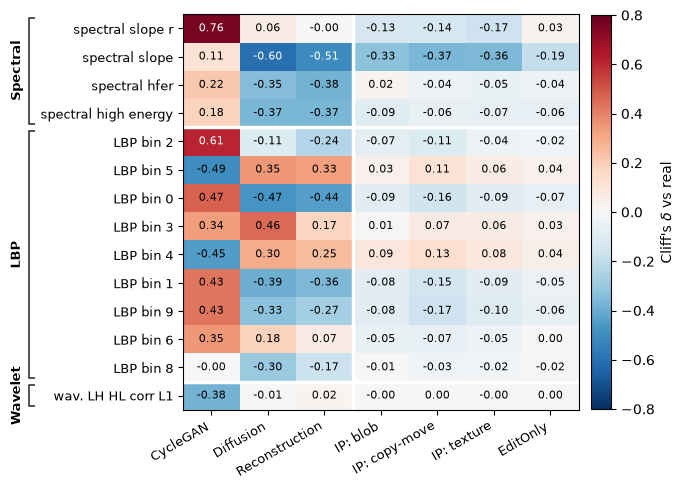

In [18]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import config
import stage3_forensics.statistical_analysis as sa

OUT = config.FORENSIC_ANALYSIS_DIR
LABEL = {"CycleGAN": "CycleGAN", "Diffusion": "Diffusion", "Diffusion_Reconstruction": "Reconstruction",
         "IP_Blob": "IP: blob", "IP_CopyMove": "IP: copy-move",
         "IP_TextureTransplant": "IP: texture", "Diffusion_EditOnly": "EditOnly"}
ORDER = list(LABEL)
FAM_NAME = {"spectral": "Spectral", "lbp": "LBP", "wavelet": "Wavelet", "srm": "SRM", "noise": "Laplacian"}
FAM_ORDER = ["spectral", "lbp", "wavelet", "srm", "noise"]

def pretty(f):
    if f.startswith("lbp_bin_"):
        return f"LBP bin {int(f[-2:])}"
    return f.replace("wavelet_", "wav. ").replace("_corr_", " corr ").replace("_", " ")

vr = res["vs_reference"]
D = (vr[vr.feature.isin(res["kept_features"])]
     .pivot(index="feature", columns="group", values="cliffs_delta_group_vs_ref")[ORDER])
top = D.abs().max(axis=1).sort_values(ascending=False).head(14).index
fam = {f: config.FEATURE_FAMILY_OF[f] for f in top}
rows = sorted(top, key=lambda f: (FAM_ORDER.index(fam[f]), -D.loc[f].abs().max()))
D = D.loc[rows]

fig, ax = plt.subplots(figsize=(6.6, 5.0))
im = ax.imshow(D.values, cmap="RdBu_r", vmin=-0.8, vmax=0.8, aspect="auto")
ax.set_xticks(range(len(ORDER)))
ax.set_xticklabels([LABEL[g] for g in ORDER], rotation=30, ha="right", fontsize=9)
ax.set_yticks(range(len(rows)))
ax.set_yticklabels([pretty(f) for f in rows], fontsize=9)
for i in range(D.shape[0]):
    for j in range(D.shape[1]):
        v = D.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(v) > 0.5 else "black")
ax.axvline(2.5, color="white", lw=2.5)

bounds, start = [], 0                                # (family, first_row, last_row)
for k in range(1, len(rows) + 1):
    if k == len(rows) or fam[rows[k]] != fam[rows[start]]:
        bounds.append((fam[rows[start]], start, k - 1))
        if k < len(rows):
            ax.axhline(k - 0.5, color="white", lw=2.5)
        start = k

plt.colorbar(im, ax=ax, fraction=0.046, pad=0.03, label=r"Cliff's $\delta$ vs real")
plt.tight_layout()
fig.canvas.draw()
renderer = fig.canvas.get_renderer()
inv = ax.transAxes.inverted()
x0 = min(t.get_window_extent(renderer).x0 for t in ax.get_yticklabels())
x_br = inv.transform((x0 - 12, 0))[0]                # bracket spine, just left of the feature names
x_tk = inv.transform((x0 - 6, 0))[0]                 # bracket end ticks point towards the labels
x_tx = inv.transform((x0 - 24, 0))[0]                # family name, left of the bracket
tr = ax.get_yaxis_transform()                        # x in axes units, y in data units
for name, a, b in bounds:
    y0, y1 = a - 0.38, b + 0.38
    ax.plot([x_tk, x_br, x_br, x_tk], [y0, y0, y1, y1], color="#333", lw=1.2,
            transform=tr, clip_on=False, solid_capstyle="butt")
    ax.text(x_tx, (a + b) / 2, FAM_NAME[name], rotation=90, va="center", ha="center",
            fontsize=9, fontweight="bold", transform=tr, clip_on=False)
plt.savefig(OUT / "forensic_feature_delta.pdf", bbox_inches="tight")
plt.show()

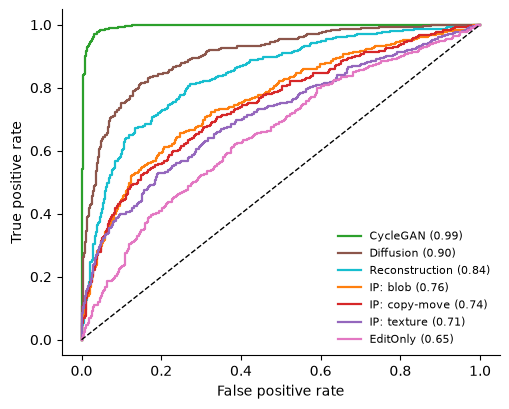

In [19]:
from sklearn.metrics import roc_curve, roc_auc_score
fig, ax = plt.subplots(figsize=(5.2, 4.2))
for g in ORDER:                                   # ORDER and LABEL from the figure cell
    c, X_, yy, _ = models[g]
    p = c.predict_proba(X_["test"])[:, 1]
    fpr, tpr, _ = roc_curve(yy["test"], p)
    ax.plot(fpr, tpr, lw=1.6, color=config.GROUP_COLOURS.get(g),
            label=f"{LABEL[g]} ({roc_auc_score(yy['test'], p):.2f})")
ax.plot([0, 1], [0, 1], "k--", lw=1)
ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
ax.legend(fontsize=8, loc="lower right", frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig(config.FORENSIC_ANALYSIS_DIR / "forensic_roc.pdf", bbox_inches="tight"); plt.show()

In [20]:
for n in ["forensic_feature_delta.pdf", "forensic_roc.pdf"]:
    p = config.FORENSIC_ANALYSIS_DIR / n
    print(p, p.exists())

/data/aa8624/thesis_2500/data/artifact_characterization/stage1_characterisation/analysis/forensic_feature_delta.pdf True
/data/aa8624/thesis_2500/data/artifact_characterization/stage1_characterisation/analysis/forensic_roc.pdf True


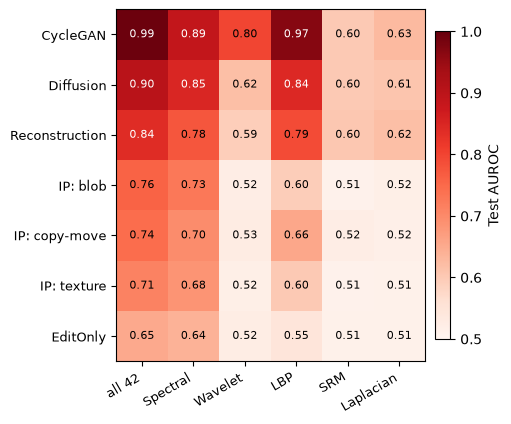

In [22]:
# Standalone AUROC heatmap (test AUROC vs real, all 42 + feature groups)
M = A[["all 42", "spectral", "wavelet", "lbp", "srm", "noise"]].astype(float)
M = M.loc[ORDER]
fig, ax = plt.subplots(figsize=(5.2, 4.4))
im = ax.imshow(M.values, cmap="Reds", vmin=0.5, vmax=1.0, aspect="auto")
ax.set_xticks(range(M.shape[1]))
ax.set_xticklabels(["all 42", "Spectral", "Wavelet", "LBP", "SRM", "Laplacian"], rotation=30, ha="right", fontsize=9)
ax.set_yticks(range(M.shape[0]))
ax.set_yticklabels([LABEL[g] for g in M.index], fontsize=9)
for i in range(M.shape[0]):
    for j in range(M.shape[1]):
        v = M.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8,
                color="white" if v > 0.8 else "black")
plt.colorbar(im, ax=ax, fraction=0.046, pad=0.03, label="Test AUROC")
plt.tight_layout()
plt.savefig(config.FORENSIC_ANALYSIS_DIR / "forensic_auroc_heatmap.pdf", bbox_inches="tight")
plt.show()

#### Stage 3d — Statistical testing - Kruskal-Wallis (H, ε²), Cliff’s delta, FDR-corrected p-values

In [21]:
# ===== reload + run feature statistics (Kruskal, group-vs-real, redundancy) =====
REF = config.REFERENCE_GROUP
res = sa.run_stage3_analysis(features, profiles=None, make_plots=False)   # train split, 8 groups

# Which features differ across groups at all (Kruskal-Wallis, epsilon^2, FDR)
print("\n1) Top 15 features by epsilon^2")
display(res["kruskal"].head(15).round(4))
print("\nFamily summary")
display(res["family_summary"].round(3))

# Each group vs Real (Cliff's delta, direction, FDR within these rows)
vr = res["vs_reference"]
print(f"\n2) Strongest features per group vs {REF} (top 5 each, by |Cliff's delta|)")
for g, d in vr.groupby("group"):
    print(f"\n{g}")
    display(d.head(5)[["feature", "family", "cliffs_delta_group_vs_ref", "magnitude",
                       "direction", "q_value_vs_ref"]].round(4))

# Redundancy: near-duplicate features that were dropped
print(f"\n3) Redundancy pruning (|rho| > {config.REDUNDANCY_SPEARMAN_THRESHOLD}):",
      len(res["kept_features"]), "kept,", len(res["redundancy"]), "dropped")
display(res["redundancy"].round(3))

Screening on split='train': 11985 images, 8 groups
frequency_group
Real                        1500
IP_Blob                     1500
IP_CopyMove                 1500
IP_TextureTransplant        1500
CycleGAN                    1500
Diffusion                   1495
Diffusion_EditOnly          1495
Diffusion_Reconstruction    1495
Redundancy pruning (Spearman |rho| > 0.95): 39 of 42 features kept, 3 dropped
Saved Stage-3 tables -> /data/aa8624/thesis_2500/data/artifact_characterization/stage1_characterisation/analysis

1) Top 15 features by epsilon^2


,feature,H,p_value,epsilon_sq,q_value,significant,family
0,spectral_slope_r,2668.4990,0.0,0.2227,0.0,True,spectral
1,lbp_bin_00,2256.3907,0.0,0.1883,0.0,True,lbp
2,lbp_bin_02,1875.3780,0.0,0.1565,0.0,True,lbp
3,lbp_bin_05,1874.3927,0.0,0.1564,0.0,True,lbp
4,lbp_bin_01,1764.5620,0.0,0.1472,0.0,True,lbp
5,spectral_slope,1731.9108,0.0,0.1445,0.0,True,spectral
6,lbp_bin_04,1406.4190,0.0,0.1174,0.0,True,lbp
7,lbp_bin_09,1402.4910,0.0,0.1170,0.0,True,lbp
8,spectral_hfer,1151.2224,0.0,0.0961,0.0,True,spectral
9,spectral_high_energy,1031.0846,0.0,0.0860,0.0,True,spectral



Family summary


,n_features,n_significant,mean_epsilon_sq,max_epsilon_sq,top_feature
family,,,,,
lbp,10,10,0.107,0.188,lbp_bin_00
spectral,6,6,0.097,0.223,spectral_slope_r
noise,5,5,0.028,0.071,noise_residual_abs_mean
srm,3,3,0.019,0.035,srm_mean_abs
wavelet,18,15,0.010,0.047,wavelet_LH_HL_corr_L1



2) Strongest features per group vs Real (top 5 each, by |Cliff's delta|)

CycleGAN


,feature,family,cliffs_delta_group_vs_ref,magnitude,direction,q_value_vs_ref
0,spectral_slope_r,spectral,0.7574,large,higher in group,0.0
1,lbp_bin_02,lbp,0.6068,large,higher in group,0.0
2,lbp_bin_05,lbp,-0.4943,large,lower in group,0.0
3,lbp_bin_00,lbp,0.4694,medium,higher in group,0.0
4,lbp_bin_04,lbp,-0.4480,medium,lower in group,0.0


... (10 outputs left out)


IP_TextureTransplant


,feature,family,cliffs_delta_group_vs_ref,magnitude,direction,q_value_vs_ref
252,spectral_slope,spectral,-0.3616,medium,lower in group,0.0000
253,spectral_slope_r,spectral,-0.1656,small,lower in group,0.0000
254,lbp_bin_09,lbp,-0.1013,negligible,lower in group,0.0000
255,lbp_bin_00,lbp,-0.0904,negligible,lower in group,0.0001
256,lbp_bin_01,lbp,-0.0900,negligible,lower in group,0.0001



3) Redundancy pruning (|rho| > 0.95): 39 kept, 3 dropped


,dropped_feature,duplicate_of,spearman_abs,family
0,noise_residual_std,noise_residual_variance,1.000,noise
1,noise_residual_rms,noise_residual_variance,1.000,noise
2,srm_variance,srm_std,0.959,srm


#### non Linear classifier

In [8]:
import time, numpy as np, pandas as pd, config
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score
from stage3_forensics.statistical_analysis import kruskal_table, transform_features
from stage4_experiments.splits import build_experiments
from stage4_experiments import runner

# gradient-boosted classifier, tuned on SOURCE validation AUROC only (same rule as the LR detectors)
GRID = [dict(max_depth=d, learning_rate=0.1, max_iter=n) for d in (2, 3) for n in (100, 300)]

def candidate_sets(train_df):
    feats = list(config.FEATURE_COLUMNS)
    out = {"spectral": [list(config.SPECTRAL_MODEL_FEATURES)],
           "lbp": [[f"lbp_bin_{i:02d}" for i in range(config.FORENSIC_LBP_HISTOGRAM_BINS)]]}
    kw = kruskal_table(train_df, feats, group_col="label", alpha=config.HANDCRAFTED_FDR_ALPHA)
    ranked = kw[kw["significant"]]["feature"].tolist() or kw["feature"].tolist()
    sets = []
    for k in sorted(config.HANDCRAFTED_TOP_K_GRID):
        if ranked[:k] not in sets:
            sets.append(ranked[:k])
    out["handcrafted"] = sets
    return out

def fit_gb(train_df, val_df, sets):
    ytr, yv = train_df["label"].to_numpy(), val_df["label"].to_numpy()
    best = {"auc": -1}
    for cols in sets:
        Xtr, Xv = transform_features(train_df, cols), transform_features(val_df, cols)
        for p in GRID:
            try:
                clf = HistGradientBoostingClassifier(random_state=42, early_stopping=False,
                                                     class_weight="balanced", **p)
            except TypeError:                          # older scikit-learn without class_weight
                clf = HistGradientBoostingClassifier(random_state=42, early_stopping=False, **p)
            clf.fit(Xtr, ytr)
            auc = roc_auc_score(yv, clf.predict_proba(Xv)[:, 1])
            if auc > best["auc"] + 1e-9:
                best = dict(auc=auc, cols=cols, clf=clf)
    return best

master = runner.load_modelling_table()
exps = build_experiments(master)            # same 20 experiments as the main grid
rows, t0 = [], time.time()
for exp in exps:
    for name, sets in candidate_sets(exp.train_df).items():
        b = fit_gb(exp.train_df, exp.val_df, sets)
        for role, df in (("test_in", exp.test_in_df), ("test_cross", exp.test_cross_df)):
            s = b["clf"].predict_proba(transform_features(df, b["cols"]))[:, 1]
            rows.append(dict(experiment=exp.name, detector=name, role=role,
                             auroc_gb=roc_auc_score(df["label"].to_numpy(), s), n_features=len(b["cols"])))
    print(f"{exp.name:<30s} done ({(time.time()-t0)/60:.1f} min)")
gb = pd.DataFrame(rows)

# compare with the existing logistic-regression results (seed 42 only, same experiments)
res = pd.read_csv(config.DET_RESULTS_CSV)
print("LR model names in results:", sorted(res.model.unique()))
LR = {"spectral": "spectral_lr", "lbp": "lbp_lr", "handcrafted": "handcrafted_lr"}   # fix names if they differ
lr = (res[(res.seed == res.seed.min()) & res.role.isin(["test_in", "test_cross"]) & res.model.isin(LR.values())]
      [["experiment", "model", "role", "auroc"]].rename(columns={"auroc": "auroc_lr"}))
lr["detector"] = lr["model"].map({v: k for k, v in LR.items()})
cmp_ = gb.merge(lr[["experiment", "detector", "role", "auroc_lr"]], on=["experiment", "detector", "role"])
cmp_["diff_gb_minus_lr"] = cmp_["auroc_gb"] - cmp_["auroc_lr"]

print(cmp_.groupby(["detector", "role"])[["auroc_lr", "auroc_gb", "diff_gb_minus_lr"]].mean().round(3))
cmp_.to_csv(config.DET_RESULTS_DIR / "check_nonlinear_classifier.csv", index=False)   # new file only

IP->CycleGAN                   done (2.0 min)
IP->Diffusion                  done (3.5 min)
IP->Diffusion_EditOnly         done (5.0 min)
IP->Diffusion_Reconstruction   done (6.7 min)
CycleGAN->IP                   done (8.4 min)
CycleGAN->Diffusion            done (10.2 min)
CycleGAN->Diffusion_EditOnly   done (12.0 min)
CycleGAN->Diffusion_Reconstruction done (13.6 min)
Diffusion->IP                  done (15.6 min)
Diffusion->CycleGAN            done (17.1 min)
Diffusion->Diffusion_EditOnly  done (18.5 min)
Diffusion->Diffusion_Reconstruction done (20.0 min)
Diffusion_EditOnly->IP         done (21.1 min)
Diffusion_EditOnly->CycleGAN   done (22.3 min)
Diffusion_EditOnly->Diffusion  done (23.3 min)
Diffusion_EditOnly->Diffusion_Reconstruction done (24.4 min)
Diffusion_Reconstruction->IP   done (26.2 min)
Diffusion_Reconstruction->CycleGAN done (27.8 min)
Diffusion_Reconstruction->Diffusion done (29.3 min)
Diffusion_Reconstruction->Diffusion_EditOnly done (31.0 min)
LR model names in r

### Check: non-linear classifier on the handcrafted features

To test whether the linear classifier limits the spectral, LBP and handcrafted detectors, each was re-fitted with gradient boosting (depth 2–3, 100 or 300 trees, tuned on source validation AUROC only) on the same features and the same 20 experiments. Mean AUROC differences from logistic regression were small (−0.006 to +0.016; spectral 0.772→0.785 in-family and 0.676→0.675 cross-generator; LBP 0.752→0.748 and 0.582→0.577; handcrafted 0.795→0.798 and 0.609→0.624). The moderate in-family AUROCs and the drop on unseen generators therefore do not appear to come from the linear decision boundary but from the information in the global features themselves. This is one fit per set without a noise estimate, so differences of this size are not interpreted. The check says nothing about spatial information, which the image-based detectors use.

#### δ-correlation check

In [9]:
import config, pandas as pd
features = pd.read_csv(config.FORENSIC_FEATURE_CSV, dtype={"subject_id": str, "study_id": str})
print(features.shape)          # expect (19973, 62)

(19973, 62)


In [10]:
import numpy as np, pandas as pd
from sklearn.metrics import roc_auc_score
import stage3_forensics.statistical_analysis as sa

REF  = config.REFERENCE_GROUP
tr   = features[(features.split == config.SCREENING_SPLIT)
                & features.frequency_group.isin(config.SCREENING_GROUPS)]
kw   = sa.kruskal_table(tr, list(config.FEATURE_COLUMNS), config.SCREENING_GROUP_COLUMN)
F, _ = sa.redundancy_pruning(tr, list(config.FEATURE_COLUMNS), kw)
ref  = tr[tr.frequency_group == REF]
fams = ["CycleGAN", "Diffusion", "Diffusion_Reconstruction", "Diffusion_EditOnly",
        "IP_Blob", "IP_CopyMove", "IP_TextureTransplant"]

def delta(g):                                   # signed Cliff's delta = 2*AUROC - 1, per feature
    t = tr[tr.frequency_group == g]
    y = np.r_[np.zeros(len(ref)), np.ones(len(t))]
    return pd.Series({f: 2 * roc_auc_score(y, np.r_[ref[f], t[f]]) - 1 for f in F})

D = pd.DataFrame({g: delta(g) for g in fams})
print("Spearman correlation of the 39 signed deltas between groups")
print("(+1 = same feature shifts in the same direction, -1 = opposite)")
print(D.corr(method="spearman").round(2).to_string())

print("\nSelected features: delta by group")
sel = ["spectral_slope", "spectral_slope_r", "spectral_hfer", "spectral_high_energy",
       "lbp_bin_00", "lbp_bin_09", "noise_residual_abs_mean"]
print(D.loc[sel].round(2).to_string())

Spearman correlation of the 39 signed deltas between groups
(+1 = same feature shifts in the same direction, -1 = opposite)
                          CycleGAN  Diffusion  Diffusion_Reconstruction  Diffusion_EditOnly  IP_Blob  IP_CopyMove  IP_TextureTransplant
CycleGAN                      1.00      -0.46                     -0.57               -0.46    -0.48        -0.67                 -0.56
Diffusion                    -0.46       1.00                      0.97                0.88     0.50         0.69                  0.61
Diffusion_Reconstruction     -0.57       0.97                      1.00                0.85     0.47         0.69                  0.58
Diffusion_EditOnly           -0.46       0.88                      0.85                1.00     0.58         0.77                  0.69
IP_Blob                      -0.48       0.50                      0.47                0.58     1.00         0.74                  0.77
IP_CopyMove                  -0.67       0.69               

### Do the groups shift the features in the same direction?

The Spearman correlation between the signed Cliff's δ vectors (39 features, train split) separates the groups into two camps. Diffusion and Reconstruction are almost identical (ρ = 0.97), EditOnly follows them (0.85–0.88), and the three classical edits resemble each other (0.74–0.93) and the Diffusion family (0.47–0.77). CycleGAN is negatively correlated with every other group (−0.46 to −0.67): `spectral_hfer`, `spectral_high_energy`, `lbp_bin_00`, `lbp_bin_09` and `noise_residual_abs_mean` are higher than real for CycleGAN (δ +0.18 to +0.47) but lower for Diffusion and Reconstruction (δ −0.25 to −0.47). The classical edits and EditOnly mainly change the spectral slope (δ −0.19 to −0.37) and leave absolute high-frequency energy and noise nearly unchanged (|δ| ≤ 0.17), whereas whole-image regeneration (Diffusion, Reconstruction) reduces high-frequency content broadly. These opposite shifts are consistent with the weak or below-chance transfer between CycleGAN and the other groups, but this link was not tested directly. Correlations are descriptive: the features are not independent, and the measure reflects direction, not magnitude.